<a href="https://colab.research.google.com/github/fathimanoorjahan03-afk/ROADSHIELD/blob/main/Road_Collision_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries

In [ ]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# 2. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Load the raw dataset

In [ ]:
raw_df = pd.read_csv('/content/drive/MyDrive/Main project/raw_data/road_collision_2023_2025.csv')

df = raw_df.copy()

print("Dataset Shape:", df.shape)

/tmp/ipykernel_561/1742831420.py:1: DtypeWarning: Columns (0,2) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv('/content/drive/MyDrive/Main project/raw_data/road_collision_2023_2025.csv')


Dataset Shape: (306710, 44)


In [ ]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (306710, 44)


In [ ]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 'collision_i

In [ ]:
# Check dataset information and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306710 entries, 0 to 306709
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   306710 non-null  object 
 1   collision_year                                    306710 non-null  int64  
 2   collision_ref_no                                  306710 non-null  object 
 3   location_easting_osgr                             306696 non-null  float64
 4   location_northing_osgr                            306696 non-null  float64
 5   longitude                                         306696 non-null  float64
 6   latitude                                          306696 non-null  float64
 7   police_force                                      306710 non-null  int64  
 8   collision_severity                                306710 non-null  int64  
 9   numb

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
collision_index,306710,306710,2023170M20483,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
collision_year,306710.0,NaN,NaN,NaN,2023.991089,0.81906,2023.0,2023.0,2024.0,2025.0,2025.0
collision_ref_no,306710,304106,340WN4702,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location_easting_osgr,306696.0,NaN,NaN,NaN,454376.735448,92567.946851,70537.0,392459.75,459313.0,529229.0,655160.0
location_northing_osgr,306696.0,NaN,NaN,NaN,276406.059085,146113.815181,10211.0,175223.75,221292.0,382951.5,1162591.0
longitude,306696.0,NaN,NaN,NaN,-1.219189,1.354358,-7.429339,-2.113301,-1.12434,-0.13697,1.75622
latitude,306696.0,NaN,NaN,NaN,52.375177,1.316367,49.91221,51.46317,51.874937,53.33999,60.34525
police_force,306710.0,NaN,NaN,NaN,27.822797,24.200117,1.0,5.0,22.0,45.0,99.0
collision_severity,306710.0,NaN,NaN,NaN,2.735418,0.473046,1.0,3.0,3.0,3.0,3.0
number_of_vehicles,306710.0,NaN,NaN,NaN,1.816951,0.689934,1.0,1.0,2.0,2.0,26.0


Inspect the raw dataset - Data quality analysis

In [ ]:
df.dtypes

,0
collision_index,object
collision_year,int64
collision_ref_no,object
location_easting_osgr,float64
location_northing_osgr,float64
longitude,float64
latitude,float64
police_force,int64
collision_severity,int64
number_of_vehicles,int64


In [ ]:
#Missing-value percentage
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
location_easting_osgr,14,0.004565
latitude,14,0.004565
longitude,14,0.004565
location_northing_osgr,14,0.004565
collision_ref_no,0,0.000000
collision_year,0,0.000000
collision_index,0,0.000000
police_force,0,0.000000
collision_severity,0,0.000000
number_of_vehicles,0,0.000000


In [ ]:
# Duplicate row analysis
print("Duplicate rows:", df.duplicated().sum())

# Duplicate collision identifiers
print(
    "Duplicate collision indexes:",
    df['collision_index'].duplicated().sum()
)

Duplicate rows: 0
Duplicate collision indexes: 0


In [ ]:
for col in df.select_dtypes(
    include=['object', 'category']
).columns:

    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False).head())


Column: collision_index
collision_index
2023170M20483    1
2023170M10633    1
2023170S11103    1
2023111343936    1
2023070054936    1
Name: count, dtype: int64

Column: collision_ref_no
collision_ref_no
340WN4702    3
340WN5592    3
340WN2262    3
340WN3822    3
340WN4612    3
Name: count, dtype: int64

Column: date
date
01/12/2023    428
26/05/2023    427
16/06/2023    419
07/07/2023    416
06/12/2023    413
Name: count, dtype: int64

Column: time
time
17:00    2949
16:00    2600
15:30    2554
18:00    2543
17:30    2435
Name: count, dtype: int64

Column: local_authority_ons_district
local_authority_ons_district
E08000025    6802
E08000035    4322
E09000033    3469
E06000065    3331
E08000032    3042
Name: count, dtype: int64

Column: local_authority_highway
local_authority_highway
E10000016    9227
E10000030    7690
E10000012    6957
E10000014    6837
E08000025    6802
Name: count, dtype: int64

Column: local_authority_highway_current
local_authority_highway_current
E10000016    92

In [ ]:
display(df.describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
collision_year,306710.0,2023.991089,0.819060,2023.000000,2023.000000,2023.000000,2023.000000,2024.000000,2025.000000,2025.000000,2025.000000,2.025000e+03
location_easting_osgr,306696.0,454376.735448,92567.946851,70537.000000,211110.900000,282562.000000,392459.750000,459313.000000,529229.000000,580493.000000,627659.050000,6.551600e+05
location_northing_osgr,306696.0,276406.059085,146113.815181,10211.000000,58519.050000,103828.750000,175223.750000,221292.000000,382951.500000,564496.000000,703441.450000,1.162591e+06
longitude,306696.0,-1.219189,1.354358,-7.429339,-4.776808,-3.779352,-2.113301,-1.124340,-0.136970,0.595273,1.310234,1.756220e+00
latitude,306696.0,52.375177,1.316367,49.912210,50.403958,50.822046,51.463170,51.874937,53.339990,54.974080,56.210892,6.034525e+01
police_force,306710.0,27.822797,24.200117,1.000000,1.000000,1.000000,5.000000,22.000000,45.000000,63.000000,99.000000,9.900000e+01
collision_severity,306710.0,2.735418,0.473046,1.000000,1.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000e+00
number_of_vehicles,306710.0,1.816951,0.689934,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,3.000000,4.000000,2.600000e+01
number_of_casualties,306710.0,1.268729,0.751479,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,4.000000,1.420000e+02
day_of_week,306710.0,4.126406,1.929590,1.000000,1.000000,1.000000,2.000000,4.000000,6.000000,7.000000,7.000000,7.000000e+00


Exploratory Data Analysis

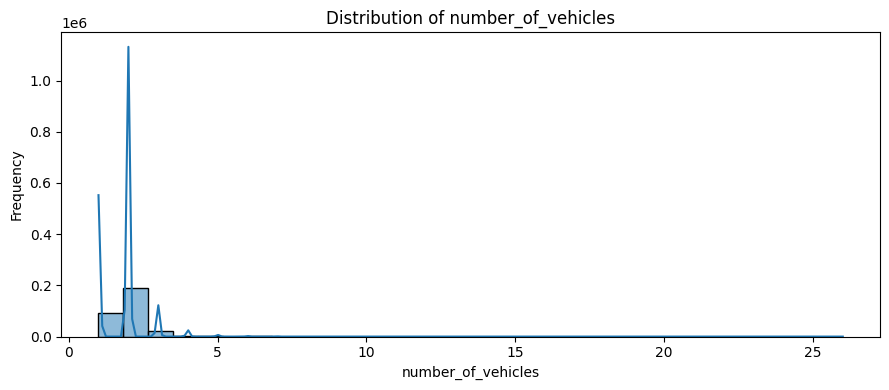

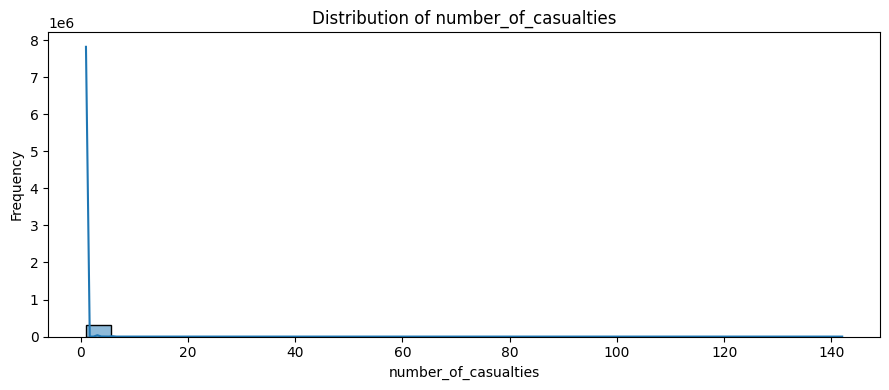

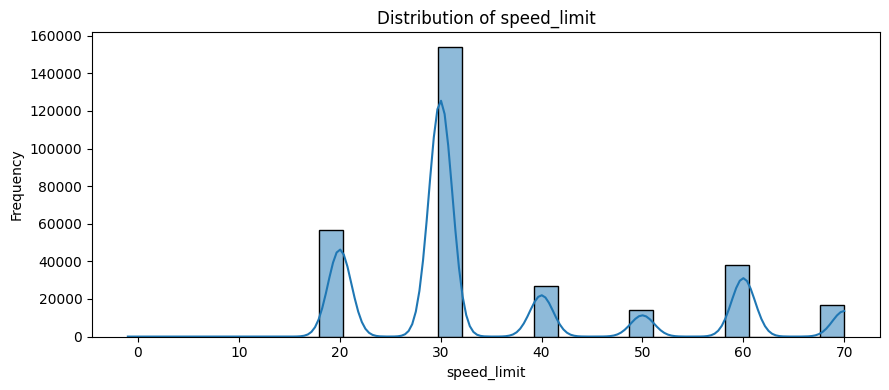

In [ ]:
numerical_cols = [
    'number_of_vehicles',
    'number_of_casualties',
    'speed_limit',

]

for col in numerical_cols:

    plt.figure(figsize=(9, 4))

    sns.histplot(
        df[col].dropna(),
        bins=30,
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [ ]:
for col in numerical_cols:

    print(f"\n{col}")
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurtosis())


number_of_vehicles
Skewness: 1.946207586921351
Kurtosis: 19.92583185835136

number_of_casualties
Skewness: 27.742746231665254
Kurtosis: 4281.297835610021

speed_limit
Skewness: 1.055468493778077
Kurtosis: -0.04961392056663749


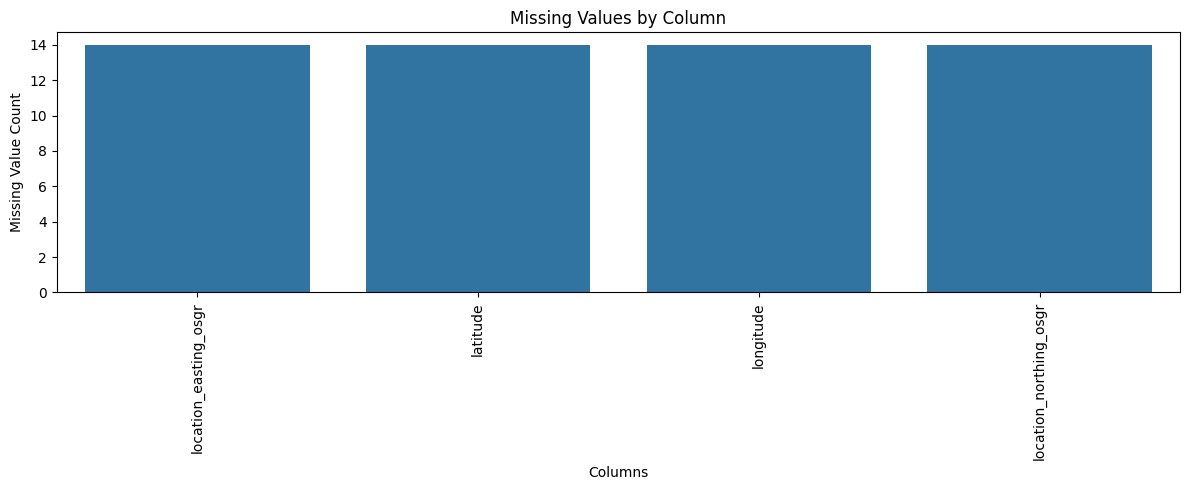

In [ ]:
#Check missing values visually

missing = missing_summary[missing_summary['Missing_Count'] > 0]

if not missing.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(
        x=missing.index,
        y=missing['Missing_Count']
    )
    plt.xticks(rotation=90)
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Value Count")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

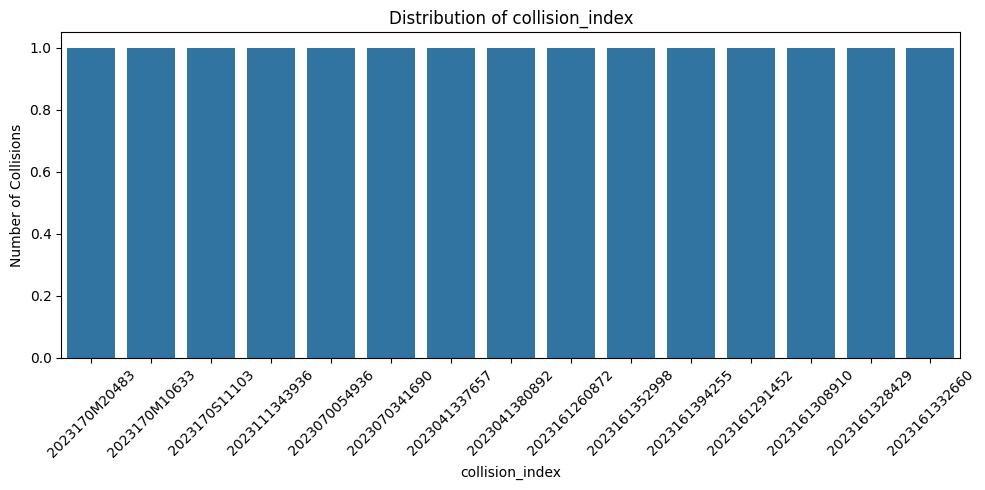

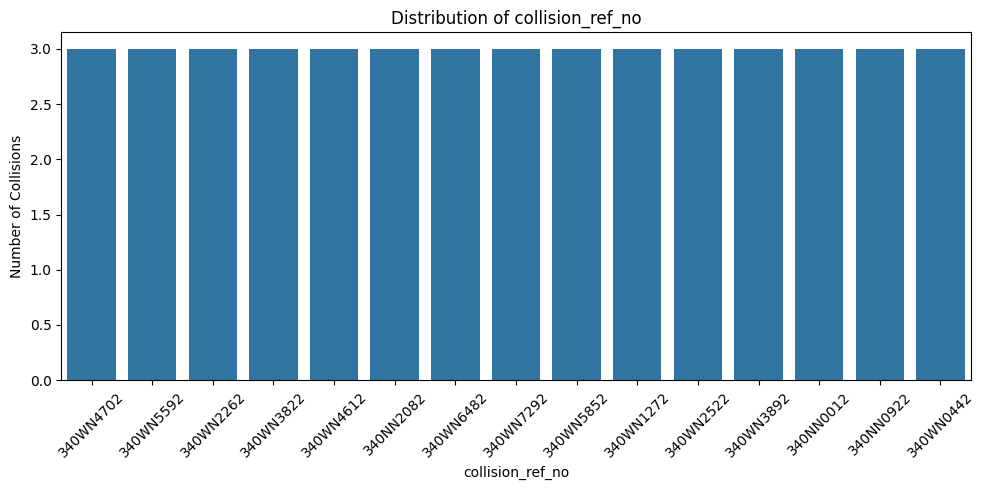

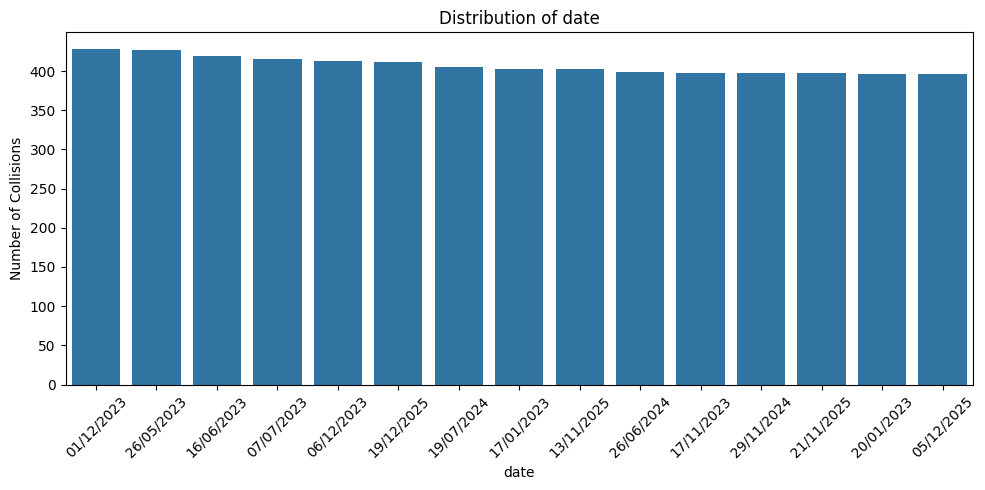

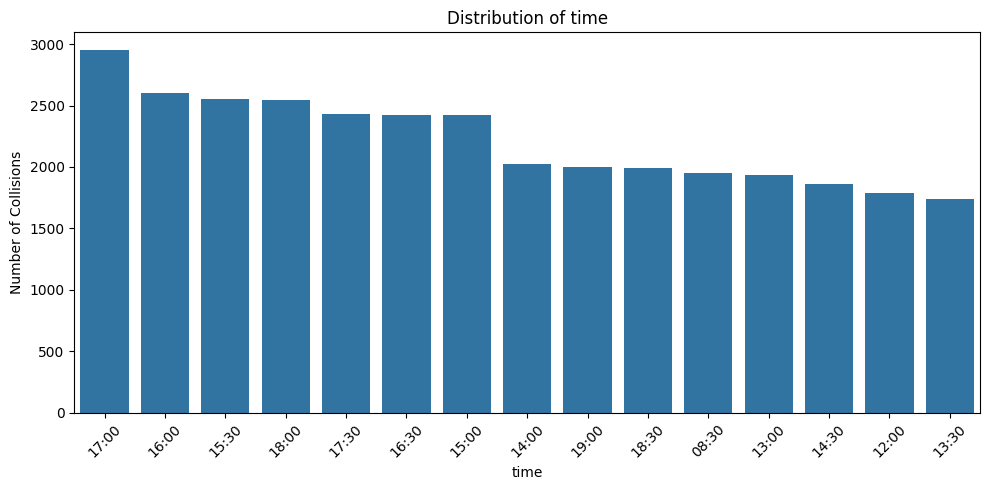

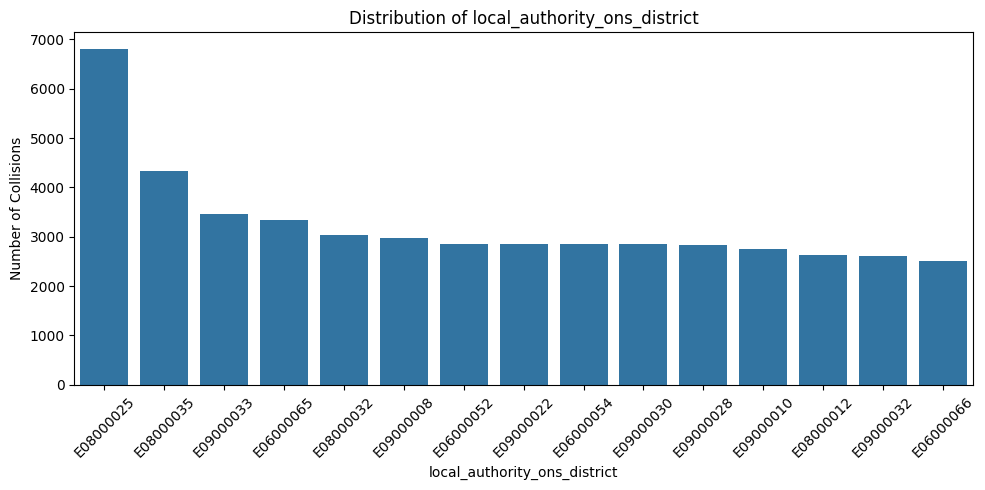

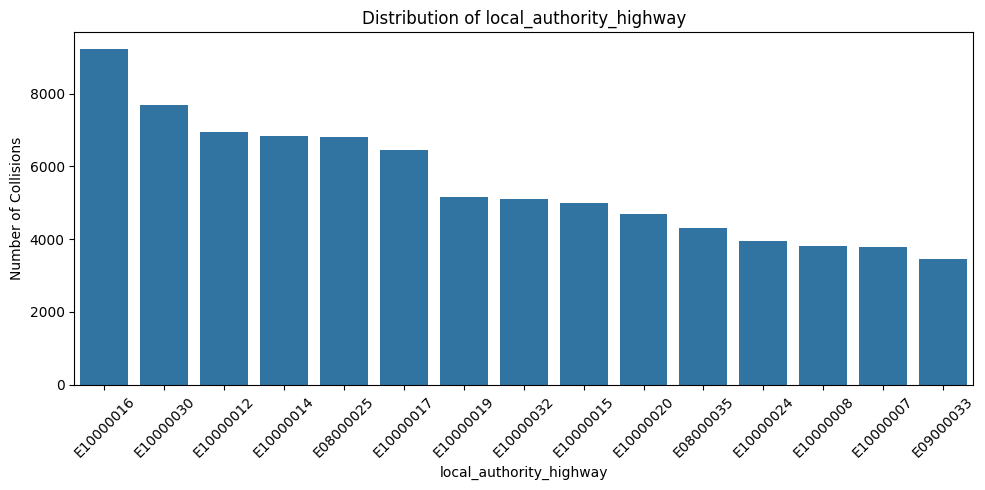

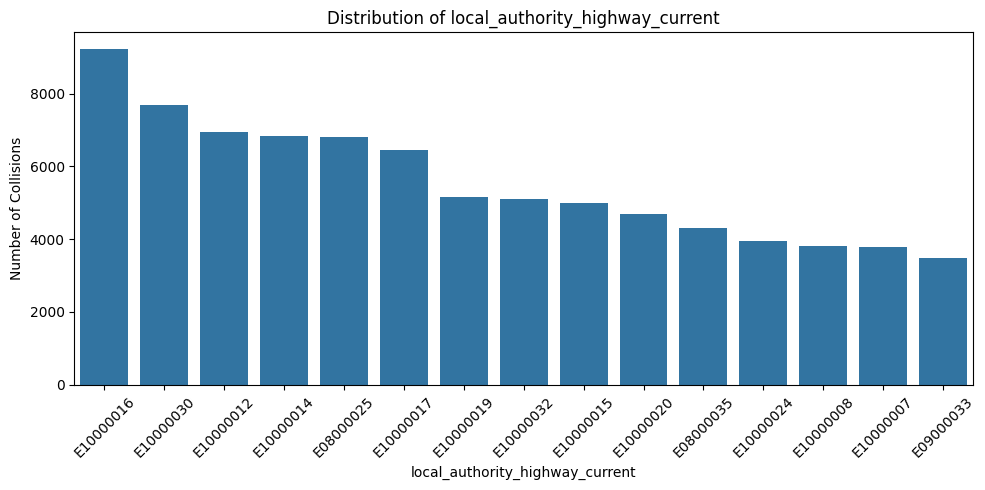

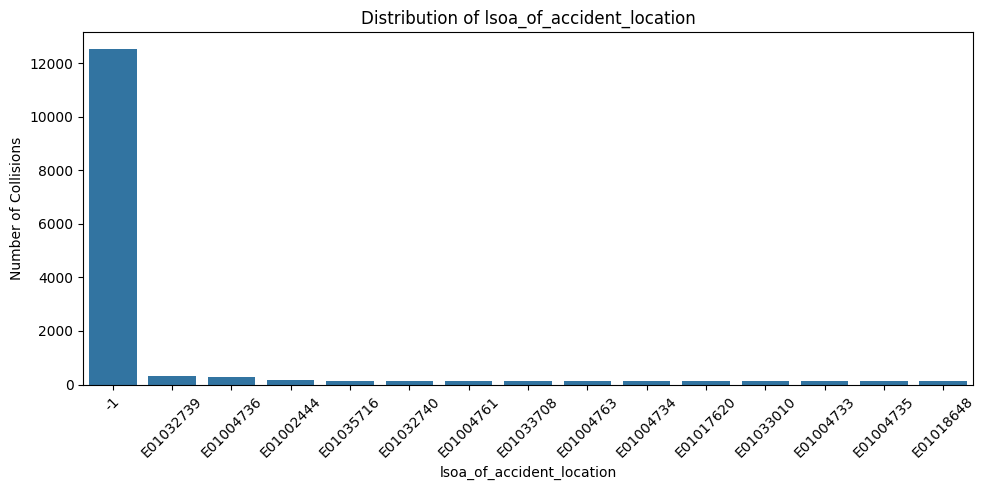

In [ ]:
#Categorical feature distributions
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    order = df[col].value_counts().head(15).index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Collisions")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

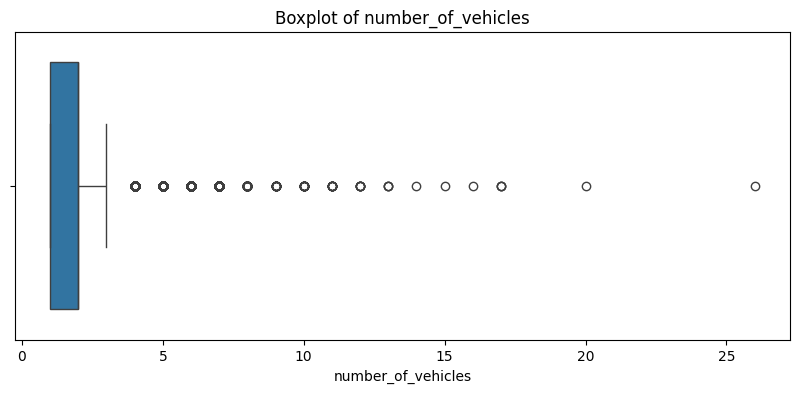

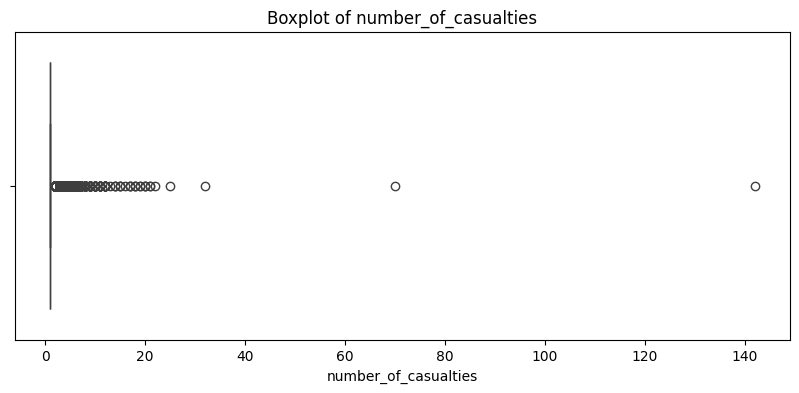

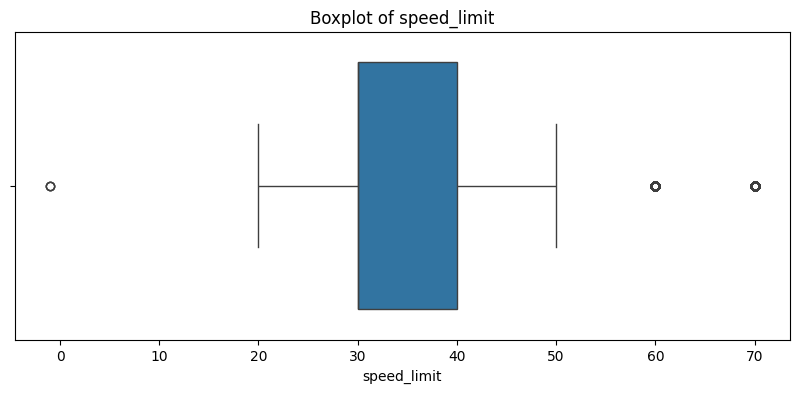

In [ ]:
#Boxplots for Numerical Features
for col in numerical_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

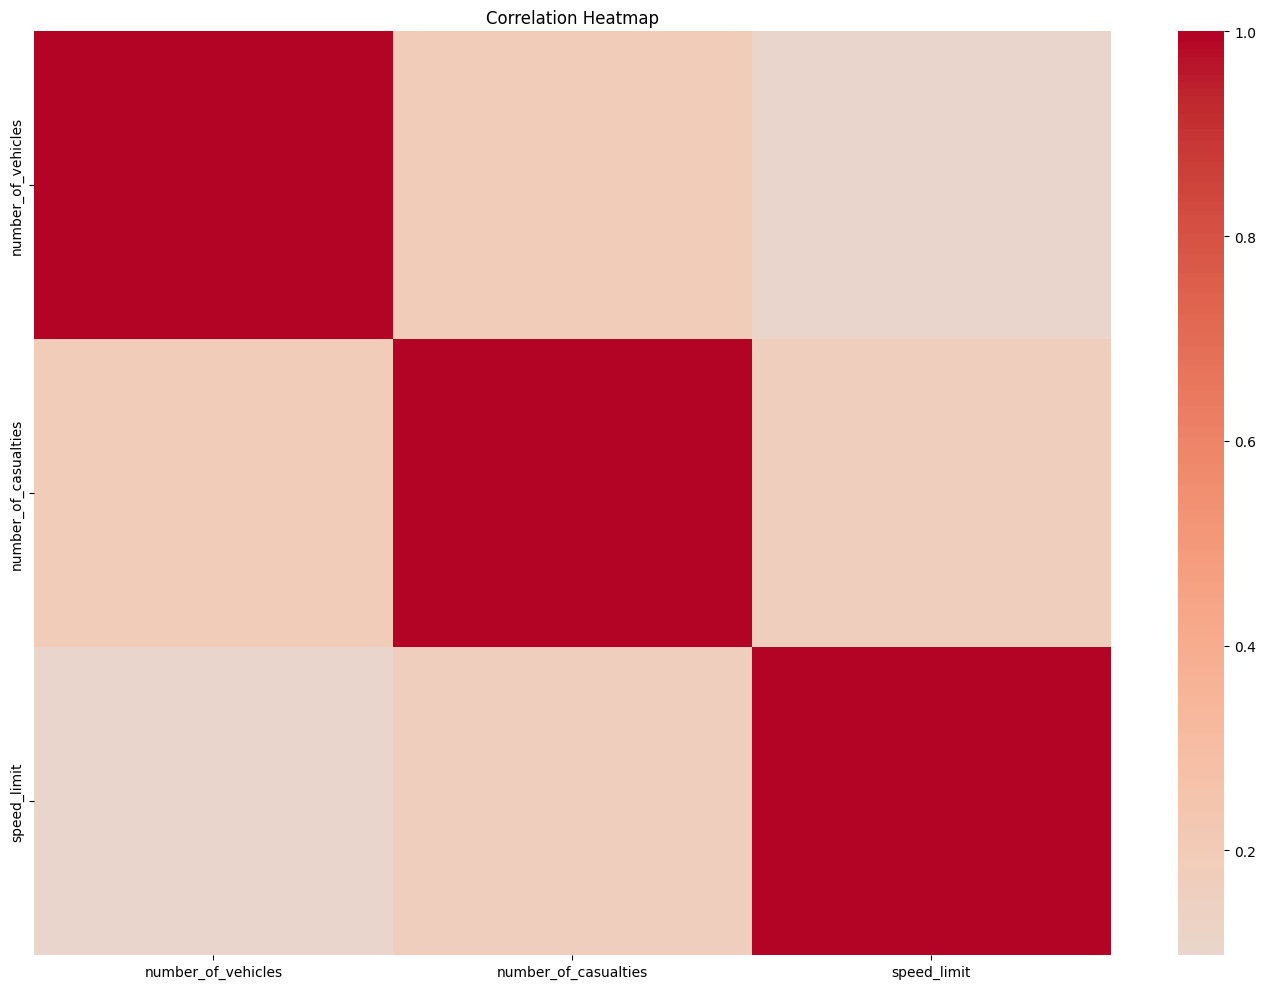

In [ ]:
#Analyze correlations between numerical features
if len(numerical_cols) >= 2:
    plt.figure(figsize=(14, 10))

    correlation_matrix = df[numerical_cols].corr()

    sns.heatmap(
        correlation_matrix,
        cmap='coolwarm',
        center=0,
        annot=False
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for correlation analysis.")

In [ ]:
df['local_authority_district'].value_counts(dropna=False)

,count
local_authority_district,
-1,306710


Target variable analysis

In [ ]:
# Value counts of target variable
df['collision_severity'].value_counts()

,count
collision_severity,
3,230037
2,72196
1,4477


In [ ]:
print("Records by year:")

year_counts = (
    df["collision_year"]
    .value_counts(dropna=False)
    .sort_index()
)

display(year_counts)

print("\nCollision severity distribution:")

severity_counts = (
    df["collision_severity"]
    .value_counts(dropna=False)
    .sort_index()
)

display(severity_counts)

Records by year:


,count
collision_year,
2023,104258
2024,100927
2025,101525



Collision severity distribution:


,count
collision_severity,
1,4477
2,72196
3,230037


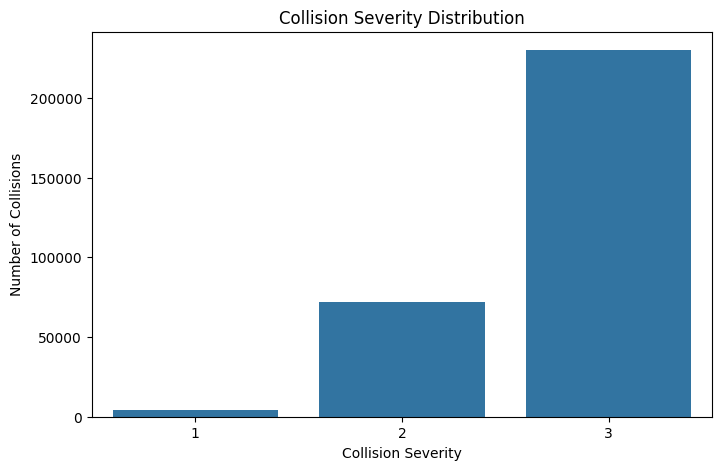

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='collision_severity')

plt.title("Collision Severity Distribution")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")
plt.show()

Bivariate analysis

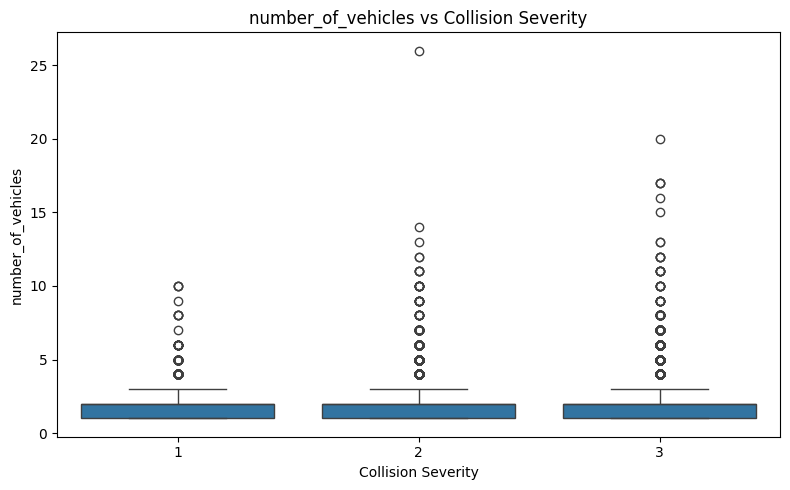

In [ ]:
# Selected numerical features for bivariate analysis
numerical_features = [
    'number_of_vehicles'
]

for col in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='collision_severity',
        y=col
    )

    plt.title(f'{col} vs Collision Severity')
    plt.xlabel('Collision Severity')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

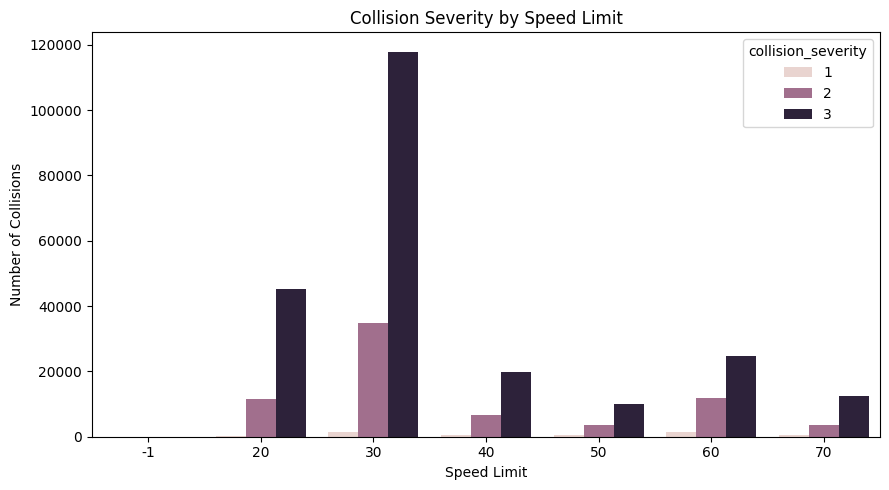

In [ ]:
#analyse speed_limit
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='speed_limit',
    hue='collision_severity'
)

plt.title('Collision Severity by Speed Limit')
plt.xlabel('Speed Limit')
plt.ylabel('Number of Collisions')
plt.tight_layout()
plt.show()

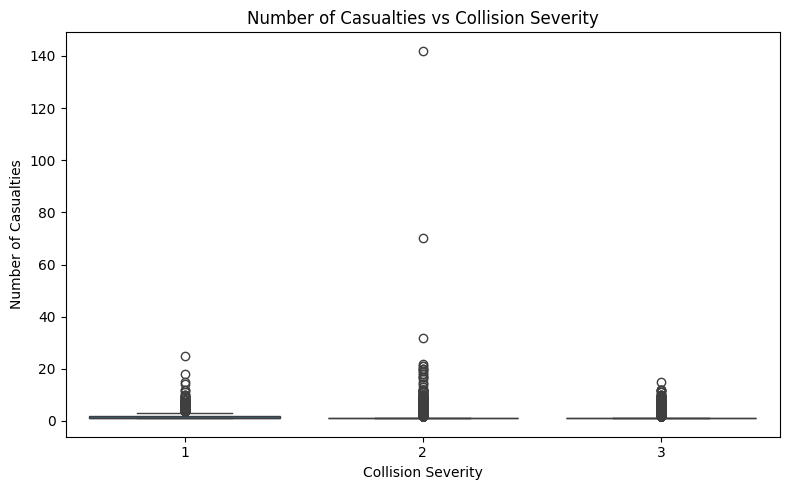

In [ ]:
#number_of_casualties vs collision severity
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='collision_severity',
    y='number_of_casualties'
)

plt.title('Number of Casualties vs Collision Severity')
plt.xlabel('Collision Severity')
plt.ylabel('Number of Casualties')
plt.tight_layout()
plt.show()

In [ ]:
# Categorical Features vs Collision Severity
categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

for col in categorical_features:

    severity_percentage = pd.crosstab(
        df[col],
        df['collision_severity'],
        normalize='index'
    ) * 100

    print(f"\n{col} vs Collision Severity (%)")
    display(severity_percentage.round(2))


collision_index vs Collision Severity (%)


collision_severity,1,2,3
collision_index,,,
2024010486807,0.0,0.0,100.0
2024010486821,0.0,0.0,100.0
2024010486824,0.0,0.0,100.0
2024010486825,0.0,0.0,100.0
2024010486828,0.0,0.0,100.0
...,...,...,...
2025991732325,0.0,0.0,100.0
2025991732815,0.0,100.0,0.0
2025991736589,0.0,0.0,100.0



collision_ref_no vs Collision Severity (%)


collision_severity,1,2,3
collision_ref_no,,,
10486807,0.0,0.0,100.0
10486821,0.0,0.0,100.0
10486824,0.0,0.0,100.0
10486825,0.0,0.0,100.0
10486828,0.0,0.0,100.0
...,...,...,...
991732325,0.0,0.0,100.0
991732815,0.0,100.0,0.0
991736589,0.0,0.0,100.0



date vs Collision Severity (%)


collision_severity,1,2,3
date,,,
01/01/2023,3.09,20.37,76.54
01/01/2024,2.37,22.27,75.36
01/01/2025,1.32,25.66,73.03
01/02/2023,3.04,19.39,77.57
01/02/2024,1.42,18.15,80.43
...,...,...,...
31/10/2024,0.71,20.36,78.93
31/10/2025,1.49,22.92,75.60
31/12/2023,0.61,20.73,78.66


... (6 outputs left out)


local_authority_highway_current vs Collision Severity (%)


collision_severity,1,2,3
local_authority_highway_current,,,
-1,0.00,35.71,64.29
E06000001,2.35,38.04,59.61
E06000002,1.24,23.76,75.00
E06000003,1.15,26.93,71.92
E06000004,2.37,26.43,71.20
...,...,...,...
W06000020,2.36,31.89,65.75
W06000021,2.88,30.03,67.09
W06000022,2.55,27.60,69.85



lsoa_of_accident_location vs Collision Severity (%)


collision_severity,1,2,3
lsoa_of_accident_location,,,
-1,3.4,40.35,56.25
E01000001,0.0,20.00,80.00
E01000002,0.0,45.45,54.55
E01000003,0.0,0.00,100.00
E01000005,0.0,26.53,73.47
...,...,...,...
W01002034,0.0,50.00,50.00
W01002035,0.0,33.33,66.67
W01002037,0.0,0.00,100.00


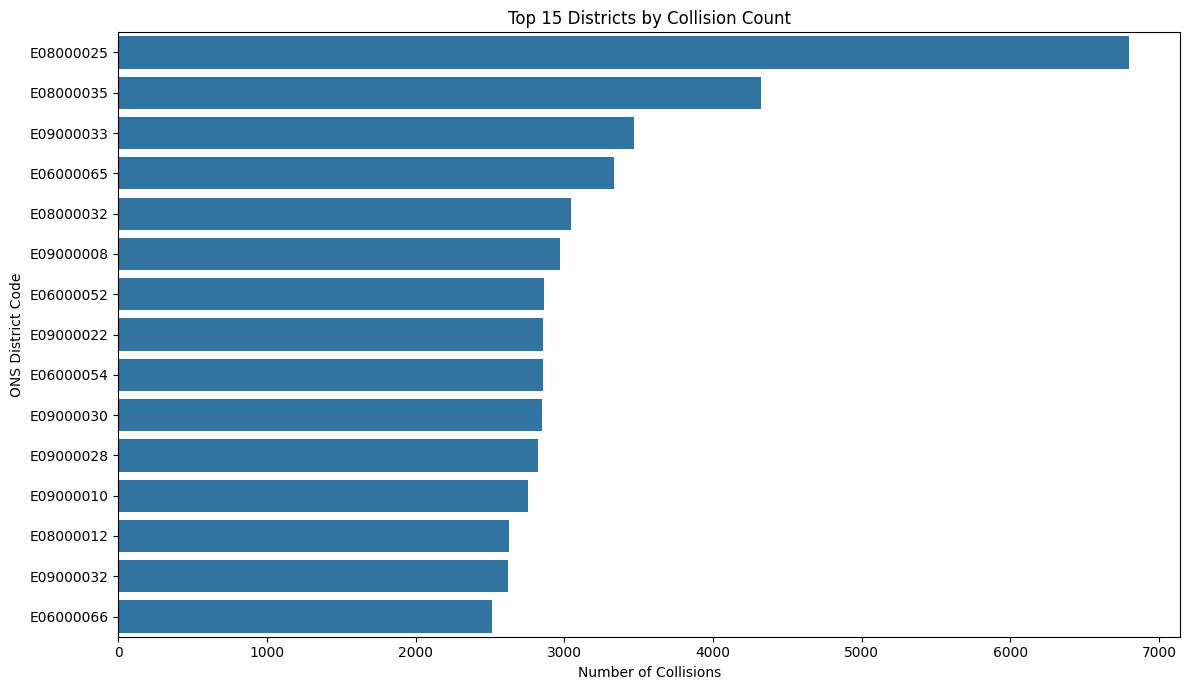

In [ ]:
# Top 15 districts by collision count

district_counts = (
    df['local_authority_ons_district']
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=district_counts.values,
    y=district_counts.index,
    orient='h'
)

plt.title("Top 15 Districts by Collision Count")
plt.xlabel("Number of Collisions")
plt.ylabel("ONS District Code")

plt.tight_layout()
plt.show()

In [ ]:
# Filter top 15 districts

top_districts = district_counts.index

# Calculate severity percentages
district_severity = pd.crosstab(
    df[df['local_authority_ons_district'].isin(top_districts)]
    ['local_authority_ons_district'],
    df['collision_severity'],
    normalize='index'
) * 100

display(district_severity.round(2))

collision_severity,1,2,3
local_authority_ons_district,,,
E06000052,2.03,21.11,76.86
E06000054,1.96,19.79,78.25
E06000065,2.94,24.62,72.44
E06000066,2.43,19.95,77.62
E08000012,0.61,21.60,77.79
E08000025,0.96,19.02,80.02
E08000032,1.02,28.44,70.55
E08000035,0.88,29.01,70.11
E09000008,0.24,15.04,84.73


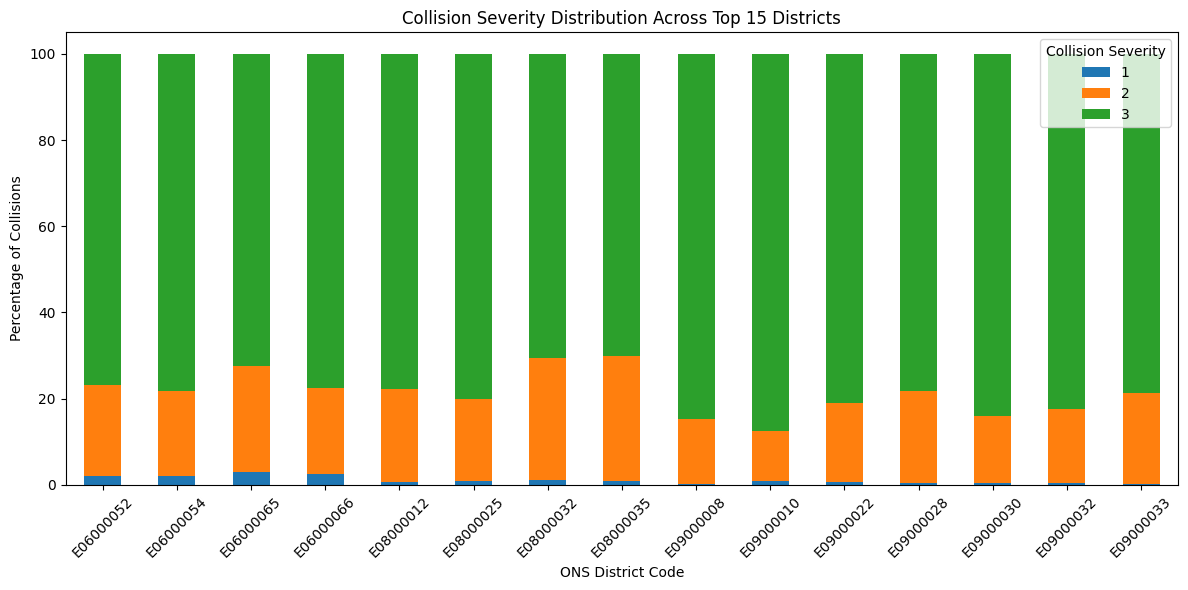

In [ ]:
district_severity.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Collision Severity Distribution Across Top 15 Districts")
plt.xlabel("ONS District Code")
plt.ylabel("Percentage of Collisions")
plt.legend(title="Collision Severity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Identify constant columns

constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant columns:")
print(constant_cols)

Constant columns:
['local_authority_district']


Temporal analysis

In [ ]:
# SECTION 11: TEMPORAL ANALYSIS

# Create a separate copy for temporal analysis
temporal_df = df.copy()

# Convert date column into datetime format
temporal_df['date_parsed'] = pd.to_datetime(
    temporal_df['date'],
    dayfirst=True,
    errors='coerce'
)

# Extract month, month name and day name
temporal_df['month'] = temporal_df['date_parsed'].dt.month

temporal_df['month_name'] = (
    temporal_df['date_parsed'].dt.month_name()
)

temporal_df['day_name'] = (
    temporal_df['date_parsed'].dt.day_name()
)

# Extract hour from time column
temporal_df['hour'] = pd.to_numeric(
    temporal_df['time'].astype(str).str.extract(
        r'^(\d{1,2}):'
    )[0],
    errors='coerce'
)

# Display extracted features
display(
    temporal_df[
        ['date', 'date_parsed', 'month_name',
         'day_name', 'time', 'hour']
    ].head(10)
)

,date,date_parsed,month_name,day_name,time,hour
0,04/03/2023,2023-03-04,March,Saturday,12:10,12
1,16/04/2023,2023-04-16,April,Sunday,20:54,20
2,27/06/2023,2023-06-27,June,Tuesday,09:30,9
3,14/08/2023,2023-08-14,August,Monday,09:03,9
4,19/01/2023,2023-01-19,January,Thursday,08:45,8
5,23/04/2023,2023-04-23,April,Sunday,13:00,13
6,02/08/2023,2023-08-02,August,Wednesday,16:30,16
7,26/11/2023,2023-11-26,November,Sunday,15:23,15
8,07/01/2023,2023-01-07,January,Saturday,10:15,10
9,15/09/2023,2023-09-15,September,Friday,17:28,17


In [ ]:
# Check invalid dates
print("Invalid dates:",
      temporal_df['date_parsed'].isna().sum())

# Check missing or invalid hours
invalid_hours = (
    temporal_df['hour'].isna()
    | ~temporal_df['hour'].between(0, 23)
)

print("Invalid or missing hours:", invalid_hours.sum())

# Check date range
print("\nDate range:")
print("Start date:", temporal_df['date_parsed'].min())
print("End date:", temporal_df['date_parsed'].max())

# Check available hours
print("\nAvailable hours:")
print(sorted(temporal_df['hour'].dropna().unique()))

Invalid dates: 0
Invalid or missing hours: 0

Date range:
Start date: 2023-01-01 00:00:00
End date: 2025-12-31 00:00:00

Available hours:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


,count
collision_year,
2023,104258
2024,100927
2025,101525


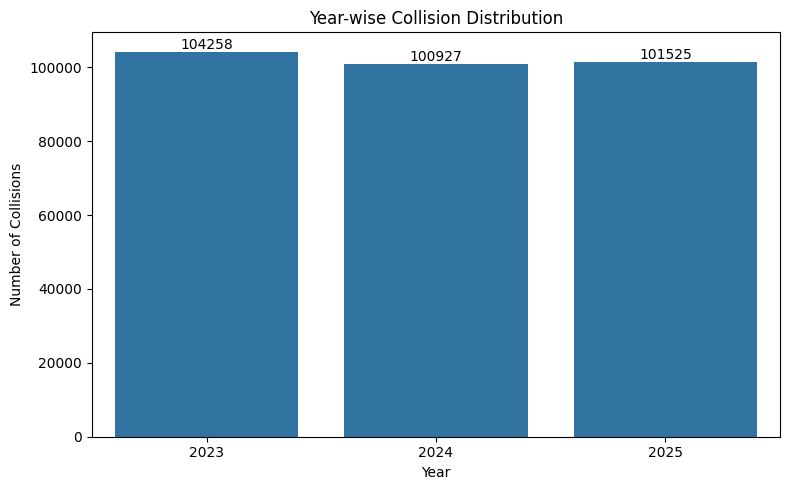

In [ ]:
# Year-wise collision distribution
year_counts = (
    temporal_df['collision_year']
    .value_counts()
    .sort_index()
)

display(year_counts)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=year_counts.index.astype(str),
    y=year_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Year-wise Collision Distribution")
plt.xlabel("Year")
plt.ylabel("Number of Collisions")
plt.tight_layout()
plt.show()

,count
month_name,
January,25218
February,22250
March,24447
April,23711
May,26907
June,27539
July,26429
August,24926
September,26436


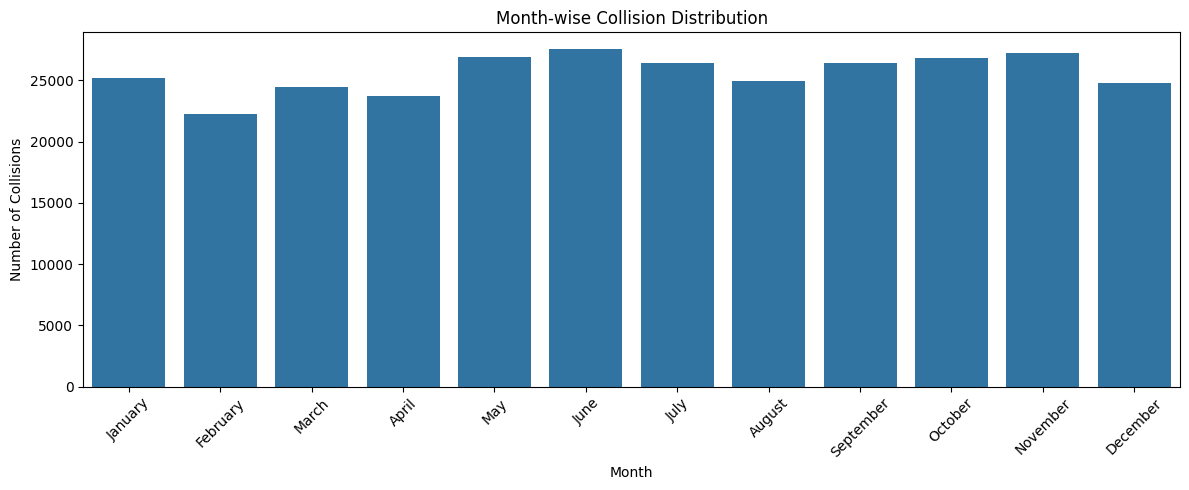

In [ ]:
# Month order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

# Month-wise collision count
monthly_counts = (
    temporal_df['month_name']
    .value_counts()
    .reindex(month_order, fill_value=0)
)

display(monthly_counts)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_counts.index,
    y=monthly_counts.values
)

plt.title("Month-wise Collision Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

collision_year,2023,2024,2025
month,,,
1,8754,8301,8163
2,7558,7537,7155
3,8183,7813,8451
4,7750,7646,8315
5,9075,8983,8849
6,9750,9064,8725
7,9162,8505,8762
8,8417,8191,8318
9,9017,8838,8581


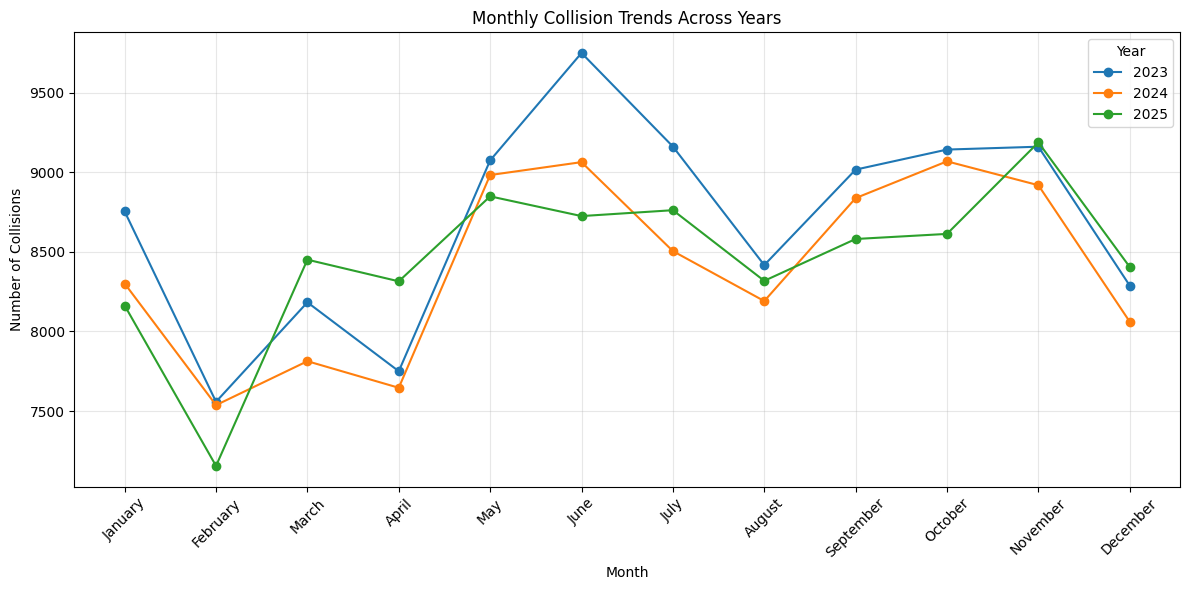

In [ ]:
# Monthly collision count across individual years
monthly_year = pd.crosstab(
    temporal_df['month'],
    temporal_df['collision_year']
)

monthly_year = monthly_year.reindex(
    range(1, 13),
    fill_value=0
)

display(monthly_year)

plt.figure(figsize=(12, 6))

for year in monthly_year.columns:
    plt.plot(
        monthly_year.index,
        monthly_year[year],
        marker='o',
        label=str(year)
    )

plt.title("Monthly Collision Trends Across Years")
plt.xlabel("Month")
plt.ylabel("Number of Collisions")
plt.xticks(
    range(1, 13),
    month_order,
    rotation=45
)
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Check the number of records available for each month and year
month_year_coverage = pd.crosstab(
    temporal_df['collision_year'],
    temporal_df['month']
)

display(month_year_coverage)

month,1,2,3,4,5,6,7,8,9,10,11,12
collision_year,,,,,,,,,,,,
2023,8754,7558,8183,7750,9075,9750,9162,8417,9017,9143,9161,8288
2024,8301,7537,7813,7646,8983,9064,8505,8191,8838,9069,8919,8061
2025,8163,7155,8451,8315,8849,8725,8762,8318,8581,8613,9188,8405


,count
day_name,
Monday,42648
Tuesday,45208
Wednesday,46033
Thursday,46556
Friday,50373
Saturday,41608
Sunday,34284


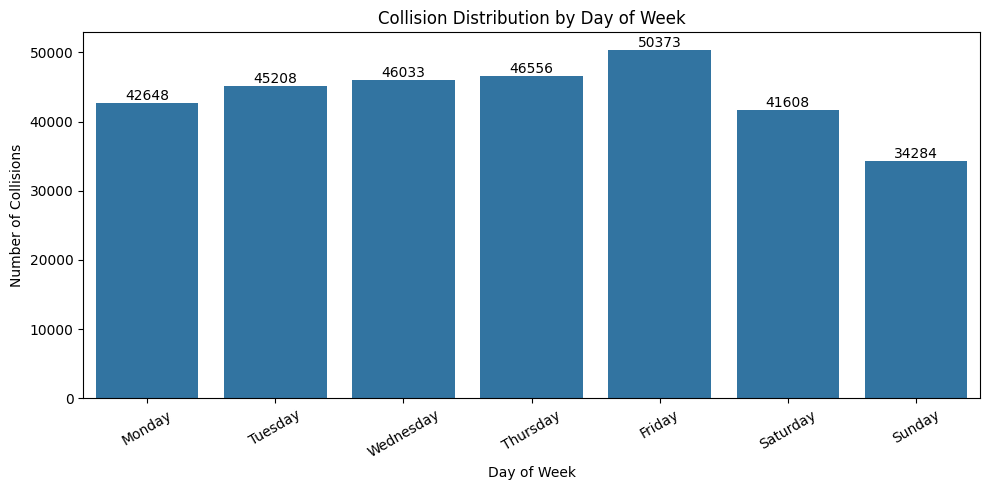

In [ ]:
# Day order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# Count collisions by day
day_counts = (
    temporal_df['day_name']
    .value_counts()
    .reindex(day_order, fill_value=0)
)

display(day_counts)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=day_counts.index,
    y=day_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Collision Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,count
hour,
0,4877
1,3317
2,2437
3,1997
4,1856
5,2925
6,5723
7,12515
8,19917


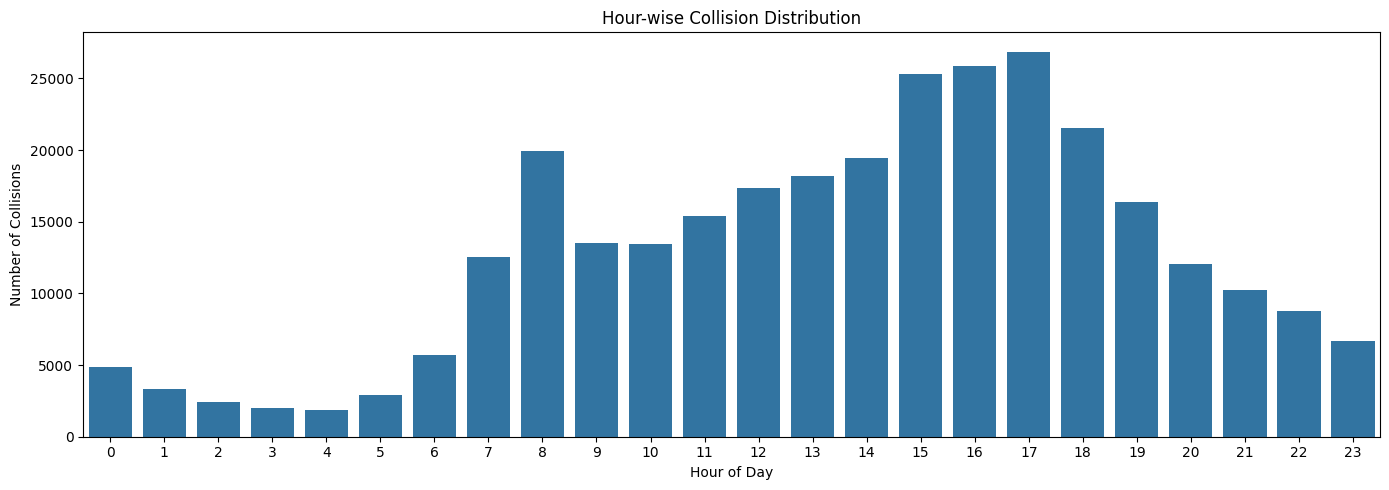

In [ ]:
# Hour-wise collision count
hour_counts = (
    temporal_df['hour']
    .value_counts()
    .reindex(range(24), fill_value=0)
)

display(hour_counts)

plt.figure(figsize=(14, 5))

sns.barplot(
    x=hour_counts.index,
    y=hour_counts.values
)

plt.title("Hour-wise Collision Distribution")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Collisions")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

collision_severity,1,2,3
collision_year,,,
2023,1.46,22.48,76.06
2024,1.49,23.35,75.16
2025,1.43,24.81,73.76


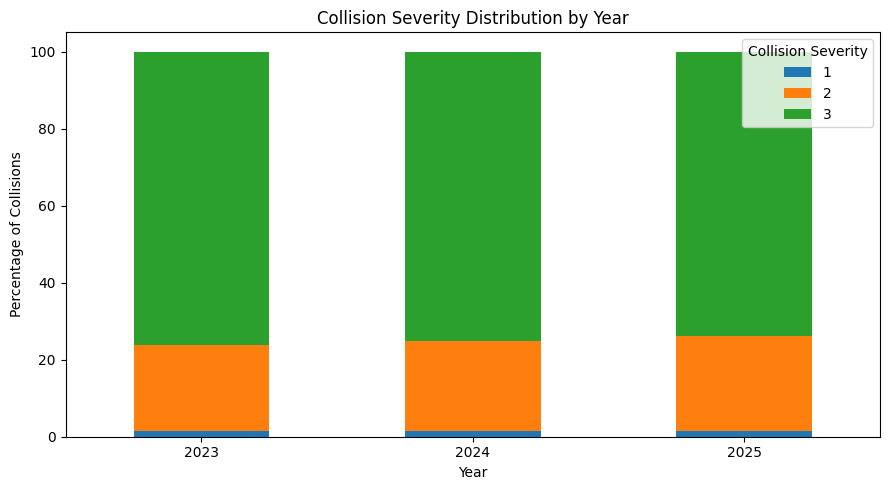

In [ ]:
#Temporal analysis based on target variable
# Severity distribution by year
year_severity_pct = pd.crosstab(
    temporal_df['collision_year'],
    temporal_df['collision_severity'],
    normalize='index'
) * 100

display(year_severity_pct.round(2))

year_severity_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title("Collision Severity Distribution by Year")
plt.xlabel("Year")
plt.ylabel("Percentage of Collisions")
plt.xticks(rotation=0)
plt.legend(title="Collision Severity")
plt.tight_layout()
plt.show()

collision_severity,1,2,3
month_name,,,
January,1.38,21.96,76.66
February,1.26,22.36,76.38
March,1.43,22.46,76.12
April,1.49,23.72,74.78
May,1.47,24.30,74.23
June,1.40,24.47,74.12
July,1.46,24.18,74.37
August,1.76,25.63,72.61
September,1.41,24.13,74.46


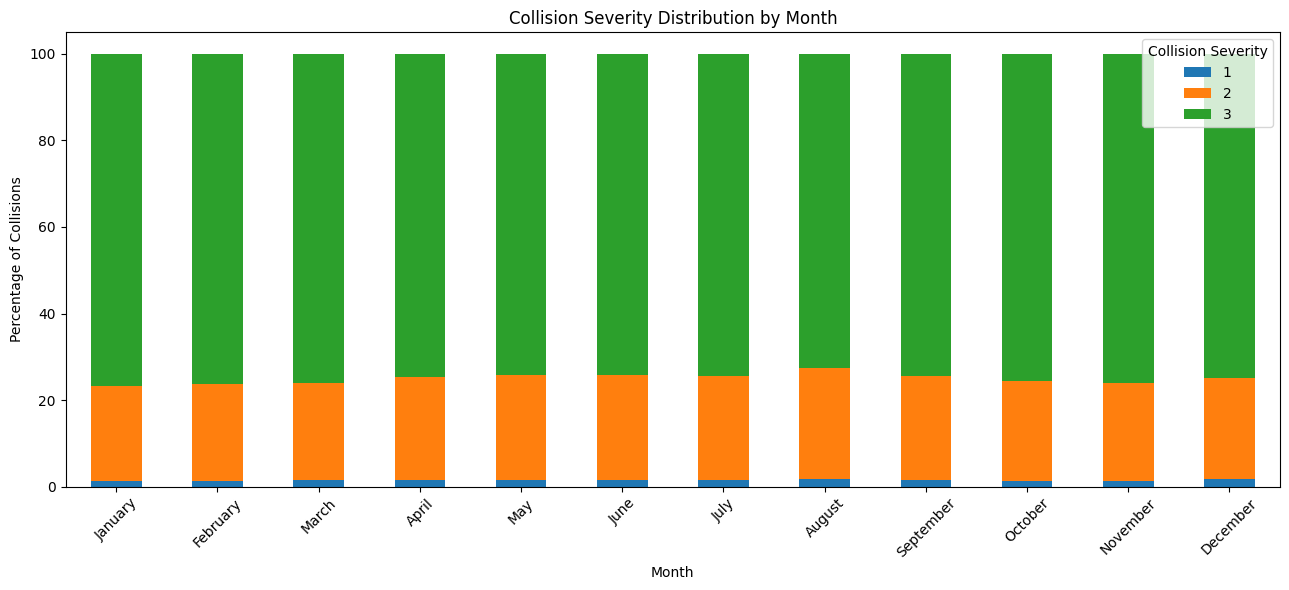

In [ ]:
# Severity percentage by month
month_severity_pct = pd.crosstab(
    temporal_df['month_name'],
    temporal_df['collision_severity'],
    normalize='index'
) * 100

month_severity_pct = month_severity_pct.reindex(month_order)

display(month_severity_pct.round(2))

month_severity_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 6)
)

plt.title("Collision Severity Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Percentage of Collisions")
plt.xticks(rotation=45)
plt.legend(title="Collision Severity")
plt.tight_layout()
plt.show()

collision_severity,1,2,3
hour,,,
0,2.99,28.34,68.67
1,2.71,27.28,70.00
2,3.41,29.09,67.50
3,3.25,27.39,69.35
4,3.77,27.53,68.70
5,3.35,27.11,69.54
6,1.96,25.13,72.92
7,1.17,22.34,76.48
8,0.80,19.16,80.04


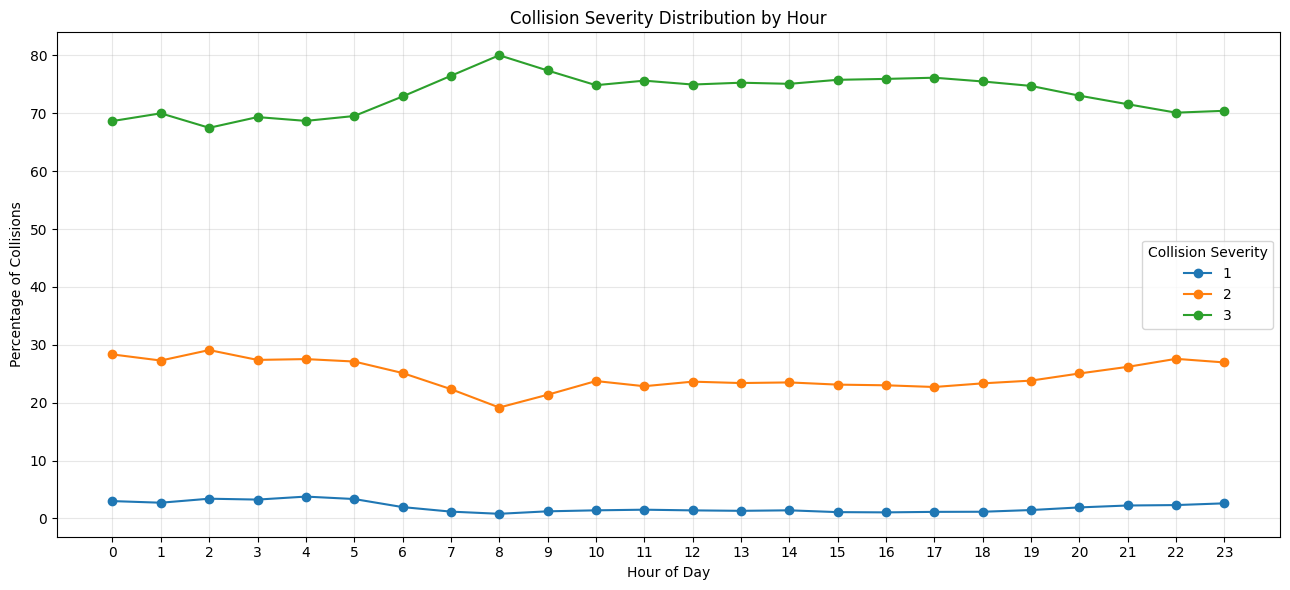

In [ ]:
# Severity percentage by hour
hour_severity_pct = pd.crosstab(
    temporal_df['hour'],
    temporal_df['collision_severity'],
    normalize='index'
) * 100

hour_severity_pct = hour_severity_pct.reindex(range(24))

display(hour_severity_pct.round(2))

hour_severity_pct.plot(
    kind='line',
    figsize=(13, 6),
    marker='o'
)

plt.title("Collision Severity Distribution by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Percentage of Collisions")
plt.xticks(range(24))
plt.legend(title="Collision Severity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

collision_severity,1,2,3
day_name,,,
Monday,1.47,22.86,75.68
Tuesday,1.23,22.33,76.44
Wednesday,1.27,22.94,75.80
Thursday,1.33,22.70,75.97
Friday,1.45,23.19,75.36
Saturday,1.72,25.54,72.75
Sunday,1.88,26.02,72.10


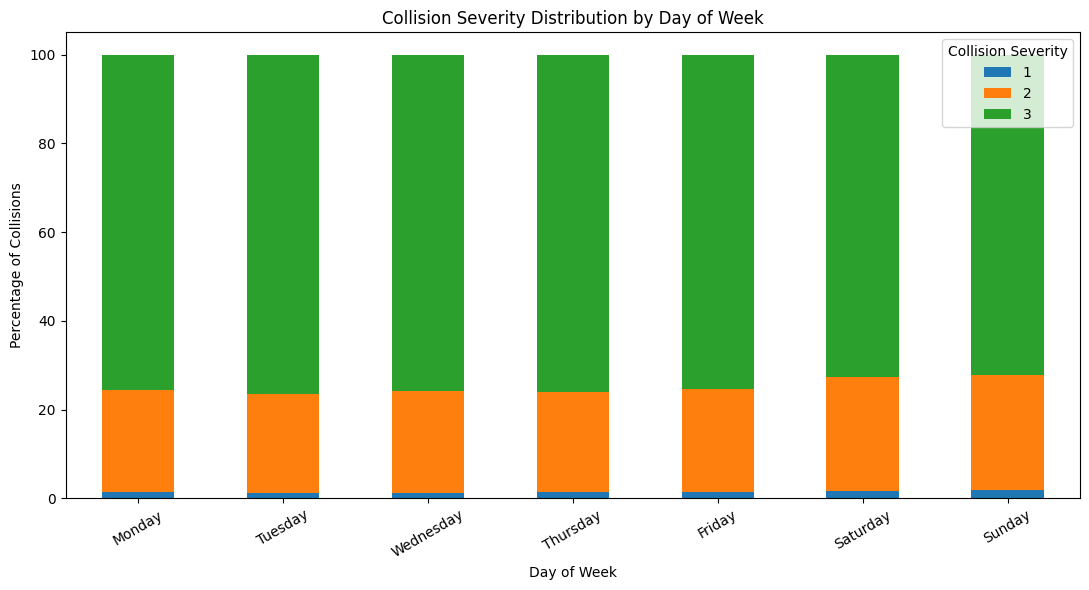

In [ ]:
# Severity percentage by day
day_severity_pct = pd.crosstab(
    temporal_df['day_name'],
    temporal_df['collision_severity'],
    normalize='index'
) * 100

day_severity_pct = day_severity_pct.reindex(day_order)

display(day_severity_pct.round(2))

day_severity_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title("Collision Severity Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Percentage of Collisions")
plt.xticks(rotation=30)
plt.legend(title="Collision Severity")
plt.tight_layout()
plt.show()

In [ ]:
# Identify geographical columns
geo_cols = [
    'latitude',
    'longitude',
    'local_authority_ons_district'
]

display(df[geo_cols].head())

print("Missing geographical values:")
display(df[geo_cols].isnull().sum())

print("\nUnique districts:",
      df['local_authority_ons_district'].nunique())

,latitude,longitude,local_authority_ons_district
0,54.565548,-1.210024,E06000002
1,54.562855,-1.224443,E06000002
2,54.561334,-1.329383,E06000004
3,54.549692,-1.587814,E06000005
4,53.432995,-2.581866,E06000007


Missing geographical values:


,0
latitude,14
longitude,14
local_authority_ons_district,0



Unique districts: 353


In [ ]:
# Geographical coordinate analysis

print("Latitude summary:")
display(df['latitude'].describe())

print("\nLongitude summary:")
display(df['longitude'].describe())

print("\nMissing coordinates:")
print(df[['latitude', 'longitude']].isnull().sum())

print("\nInvalid latitude values:",
      ((df['latitude'] < -90) | (df['latitude'] > 90)).sum())

print("Invalid longitude values:",
      ((df['longitude'] < -180) | (df['longitude'] > 180)).sum())

Latitude summary:


,latitude
count,306696.000000
mean,52.375177
std,1.316367
min,49.912210
25%,51.463170
50%,51.874937
75%,53.339990
max,60.345250



Longitude summary:


,longitude
count,306696.000000
mean,-1.219189
std,1.354358
min,-7.429339
25%,-2.113301
50%,-1.124340
75%,-0.136970
max,1.756220



Missing coordinates:
latitude     14
longitude    14
dtype: int64

Invalid latitude values: 0
Invalid longitude values: 0


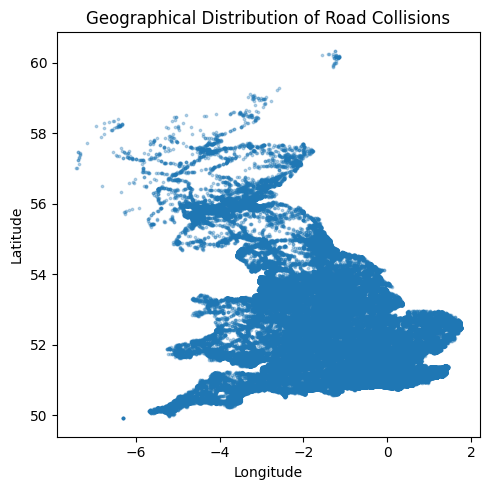

In [ ]:
# Remove missing coordinates
geo_df = df.dropna(
    subset=['latitude', 'longitude']
).copy()

plt.figure(figsize=(5, 5))

plt.scatter(
    geo_df['longitude'],
    geo_df['latitude'],
    s=3,
    alpha=0.3
)

plt.title('Geographical Distribution of Road Collisions')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

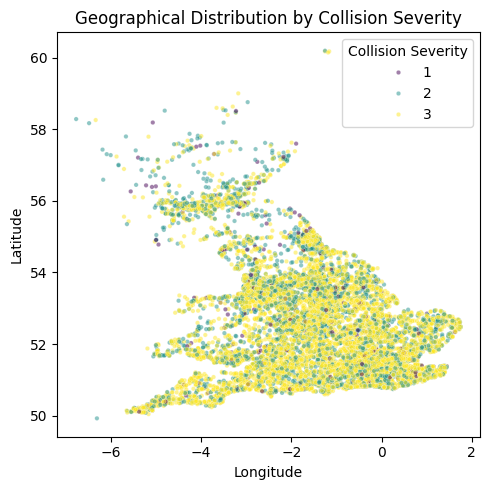

In [ ]:
# Sample records for a clearer severity-based plot
geo_sample = geo_df.sample(
    n=min(30000, len(geo_df)),
    random_state=42
)

plt.figure(figsize=(5, 5))

sns.scatterplot(
    data=geo_sample,
    x='longitude',
    y='latitude',
    hue='collision_severity',
    alpha=0.5,
    s=10,
    palette='viridis'
)

plt.title('Geographical Distribution by Collision Severity')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Collision Severity')
plt.tight_layout()
plt.show()

 EDA conclusion for geographical analysis


The geographical analysis identified 306,696 records with valid latitude and longitude values and 14 records with missing coordinates. No invalid coordinate values were detected. The dataset contains 353 unique ONS district codes. Geographical scatter plots were used to examine the spatial distribution of collisions and their severity categories. The missing coordinate records will be retained during EDA and handled appropriately during preprocessing.

In [ ]:
#Road and environmental analysis
# Identify road and environmental features

road_environment_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in [
        'road',
        'speed',
        'weather',
        'light',
        'surface',
        'junction',
        'carriageway',
        'hazard'
    ])
]

print("Road and Environmental Features:")
print(road_environment_cols)

display(df[road_environment_cols].head())

Road and Environmental Features:
['first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'carriageway_hazards_historic', 'carriageway_hazards', 'trunk_road_flag', 'collision_adjusted_severity_slight']


,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,light_conditions,weather_conditions,road_surface_conditions,carriageway_hazards_historic,carriageway_hazards,trunk_road_flag,collision_adjusted_severity_slight
0,6,0,6,30,6,16,4,6,0,1,1,1,0,0,2,0.96574
1,3,172,6,30,3,13,4,6,0,4,1,1,0,0,2,0.00000
2,5,0,6,30,3,13,4,6,0,1,1,1,0,0,2,0.94928
3,3,68,1,60,1,0,4,3,68,1,2,5,0,0,2,0.00000
4,6,0,6,30,3,13,4,5,0,1,1,4,0,0,2,0.99634


In [ ]:
#Analyse road type against collision severity
# Road and Environmental Features vs Collision Severity


road_features = [
    'road_type',
    'speed_limit',
    'first_road_class',
    'junction_detail',
    'junction_control',
    'light_conditions',
    'weather_conditions',
    'road_surface_conditions',
    'carriageway_hazards'
]


for col in road_features:

    print("\n" + "=" * 70)
    print(f"ANALYSIS: {col.upper()}")
    print("=" * 70)

    # Feature distribution
    print("\nFeature Distribution:")
    display(df[col].value_counts(dropna=False).sort_index())

    # Feature vs collision severity percentages
    severity_percentage = pd.crosstab(
        df[col],
        df['collision_severity'],
        normalize='index'
    ) * 100

    print("\nCollision Severity Distribution (%):")
    display(severity_percentage.round(2))


ANALYSIS: ROAD_TYPE

Feature Distribution:


,count
road_type,
1,18946
2,6858
3,44693
6,223453
7,5062
9,7698



Collision Severity Distribution (%):


collision_severity,1,2,3
road_type,,,
1,0.58,17.34,82.08
2,0.34,18.56,81.10
3,1.98,21.72,76.30
6,1.52,25.24,73.24
7,1.05,17.64,81.31
9,0.13,8.39,91.48



ANALYSIS: SPEED_LIMIT

Feature Distribution:


,count
speed_limit,
-1,3
20,56868
30,154107
40,26989
50,13883
60,38147
70,16713


... (26 outputs left out)


ANALYSIS: CARRIAGEWAY_HAZARDS

Feature Distribution:


,count
carriageway_hazards,
-1,8853
0,278531
11,929
12,608
13,3463
14,363
15,881
16,561
17,2758



Collision Severity Distribution (%):


collision_severity,1,2,3
carriageway_hazards,,,
-1,0.90,15.83,83.27
0,1.51,24.04,74.45
11,1.08,21.96,76.96
12,1.32,25.82,72.86
13,1.36,21.80,76.84
14,0.83,33.61,65.56
15,0.34,27.81,71.85
16,0.53,23.89,75.58
17,2.18,30.75,67.08


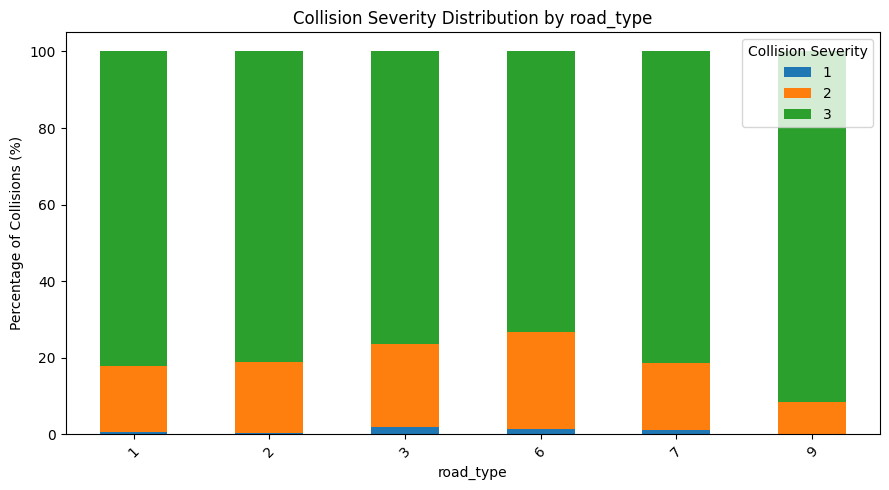

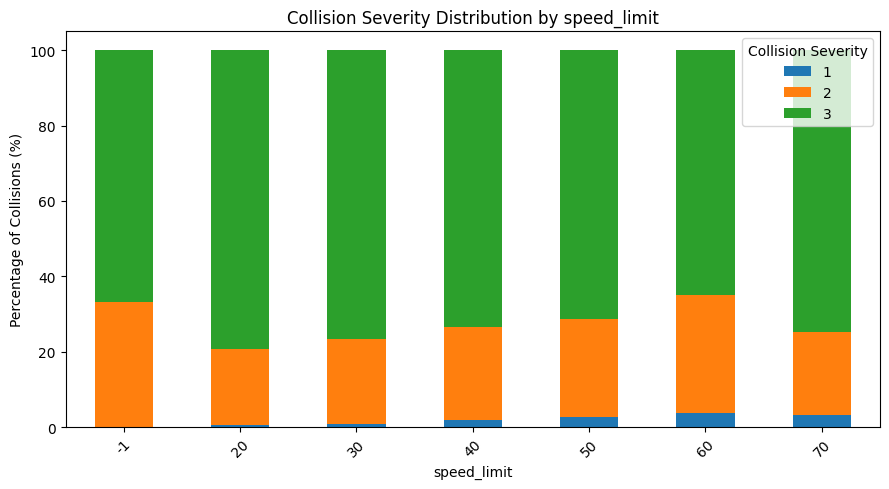

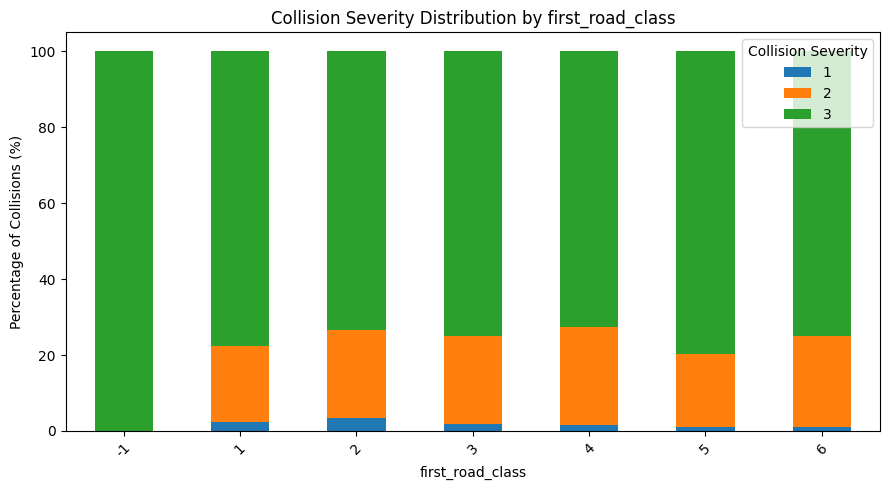

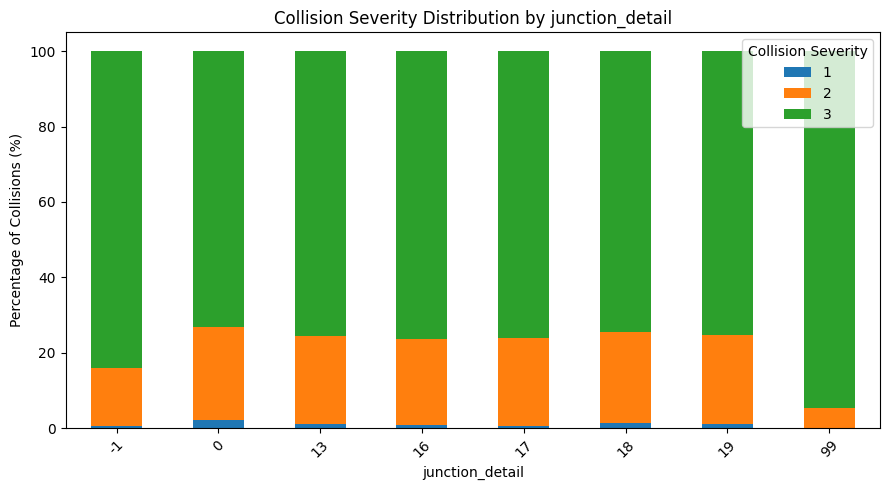

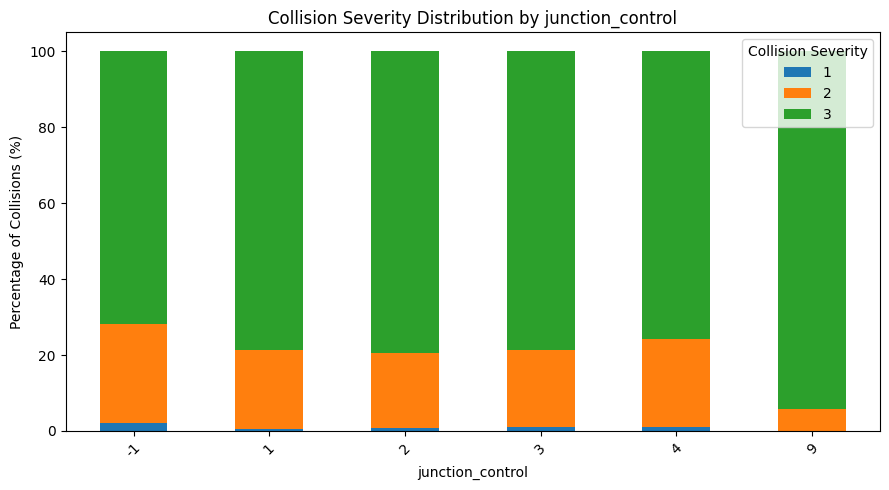

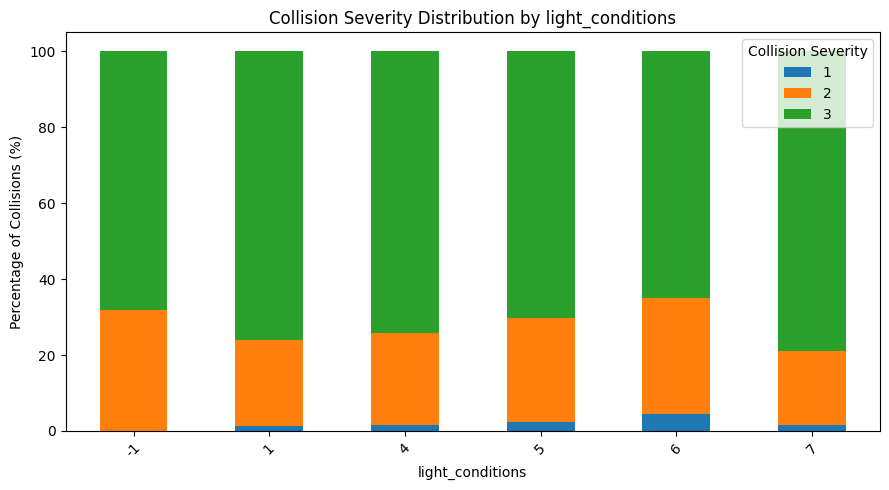

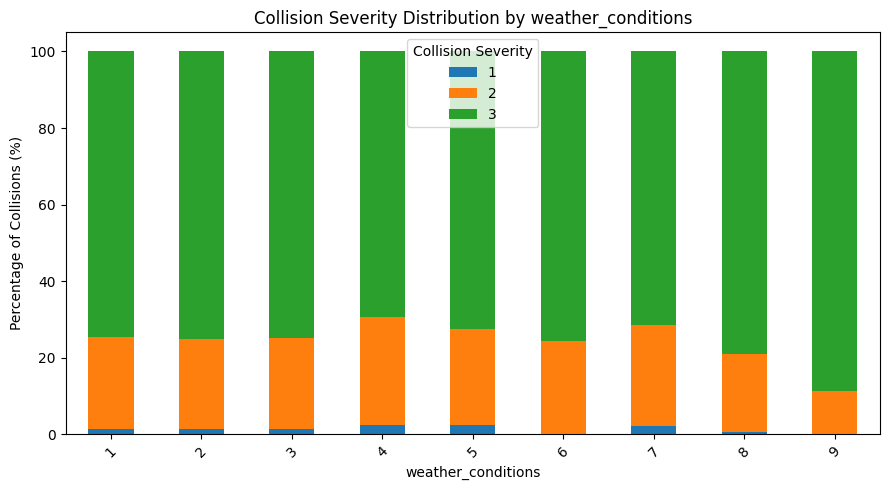

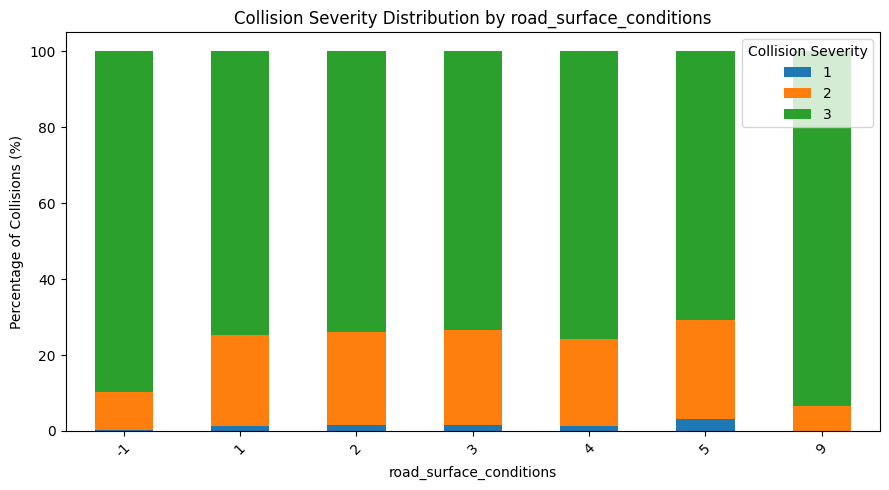

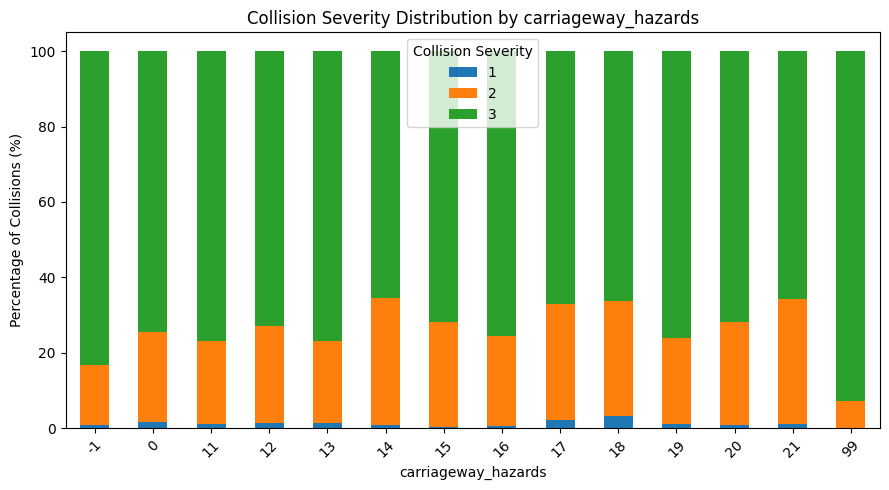

In [ ]:
# Severity distribution visualization

for col in road_features:

    severity_percentage = pd.crosstab(
        df[col],
        df['collision_severity'],
        normalize='index'
    ) * 100

    severity_percentage.plot(
        kind='bar',
        stacked=True,
        figsize=(9, 5)
    )

    plt.title(f'Collision Severity Distribution by {col}')
    plt.xlabel(col)
    plt.ylabel('Percentage of Collisions (%)')
    plt.legend(title='Collision Severity')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()